**CLAP-general variant (phase5m_encoder_comparison_artist_cg).** Copy of `phase5m_encoder_comparison_artist.ipynb` with the CLAP audio representation replaced by `laion/larger_clap_general` (`audio_features_clap_general.parquet`; the HF `larger_clap_music` conversion is defective, see Phase 2d and 5p). CLAP-general is added as a further audio family; `clap_rand` and `clap_det` are the defective music checkpoint. Every output carries a `_cg` suffix; the original outputs are untouched.

# Phase 5m: Encoder comparison (Phase 5e) under the artist-filtered primary protocol

Identical to Phase 5e except that every same-artist candidate is excluded from each query's ranking and from the
nDCG ideal ranking (the primary protocol from Phase 5i/5j onward). Configuration selection (layer, preprocessing,
fusion α) is redone on filtered validation. Probes do not involve retrieval and are recomputed unchanged. All outputs
carry an `_artist` suffix; the Phase 5e files are not touched.

In [1]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from sklearn.linear_model import RidgeCV, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, f1_score

warnings.filterwarnings('ignore')

ROOT = os.environ.get('MUSIC_RESEARCH_ROOT', os.path.abspath('.'))
OUT_DIR = os.path.join(ROOT, 'outputs')
ENC_DIR = os.path.join(OUT_DIR, 'encoders')
SIGMA, K, N_BOOT, SEED = 0.10, 10, 10_000, 42
ALPHAS = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
SCHEMES = {'tvt_70_15_15': '70/15/15', 'tvt_40_30_30': '40/30/30'}
rng = np.random.default_rng(SEED)

lyrics_df = pd.read_parquet(os.path.join(OUT_DIR, 'lyrics_features.parquet'))
merged    = pd.read_parquet(os.path.join(OUT_DIR, 'merged_dataset.parquet'))
cat_sids  = lyrics_df['song_id'].tolist()
cat_pos   = {s: i for i, s in enumerate(cat_sids)}

# ── Audio representations, aligned to the catalog ─────────────────────────────
a_ids = pd.read_csv(os.path.join(ENC_DIR, 'audio_song_ids.csv'))['song_id'].tolist()
a_row = [ {s: i for i, s in enumerate(a_ids)}[s] for s in cat_sids ]
a_old = pd.read_parquet(os.path.join(OUT_DIR, 'audio_features.parquet')).set_index('song_id').loc[cat_sids]
a_det = pd.read_parquet(os.path.join(OUT_DIR, 'audio_features_clap_det.parquet')).set_index('song_id').loc[cat_sids]
mert  = np.load(os.path.join(ENC_DIR, 'audio_mert.npy'))[a_row].astype(np.float64)    # (2075, 13, 768)
muq   = np.load(os.path.join(ENC_DIR, 'audio_muq.npy'))[a_row].astype(np.float64)     # (2075, 13, 1024)
AUDIO = {'clap_general': np.vstack(pd.read_parquet(os.path.join(OUT_DIR, 'audio_features_clap_general.parquet')).set_index('song_id').loc[cat_sids]['audio_clap_gen'].values).astype(np.float64),
         'clap_rand':   np.vstack(a_old['audio_clap'].values).astype(np.float64),
         'clap_det':    np.vstack(a_det['audio_clap_det'].values).astype(np.float64),
         'handcrafted': np.vstack(a_old['audio_handcrafted'].values).astype(np.float64)}
for L in range(13):
    AUDIO[f'mert_L{L}'] = mert[:, L]
    AUDIO[f'muq_L{L}']  = muq[:, L]

# ── Text representations ──────────────────────────────────────────────────────
assert pd.read_csv(os.path.join(ENC_DIR, 'text_song_ids.csv'))['song_id'].tolist() == cat_sids
TEXT = {n: np.load(os.path.join(ENC_DIR, f'text_{n}.npy')).astype(np.float64)
        for n in ['sbert_mpnet_trunc', 'sbert_mpnet_chunk', 'minilm_chunk', 'bge_chunk',
                  'emoroberta_emb', 'emoroberta_probs', 'lexicon']}
REPS = {**{f'audio:{k}': v for k, v in AUDIO.items()}, **{f'text:{k}': v for k, v in TEXT.items()}}
FAMILY = lambda r: r.split(':')[1].split('_L')[0] if '_L' in r else r.split(':')[1]

lab  = merged.set_index('song_id').loc[cat_sids]
quad = lab['quadrant'].values
Y    = lab[['arousal', 'valence']].values.astype(np.float64)
D_AV = np.linalg.norm(Y[:, None] - Y[None], axis=-1)

mm = merged[merged['is_multimodal']]
lyr_stem_to_sid = {os.path.splitext(os.path.basename(p))[0]: s for s, p in zip(mm['song_id'], mm['lyrics_path'])}
def read_split(modality, scheme, subset):
    folder = 'MERGE_Audio_Balanced' if modality == 'audio' else 'MERGE_Lyrics_Balanced'
    ids = pd.read_csv(os.path.join(ROOT, folder, 'tvt_dataframes', scheme,
                                   f'{scheme}_{subset}_{modality}_balanced.csv'))['Song']
    return set(ids.map(lyr_stem_to_sid).dropna()) if modality == 'lyrics' else set(ids)
cat = set(cat_sids)
shared = {lbl: {sub: sorted(read_split('audio', sc, sub) & read_split('lyrics', sc, sub) & cat)
                for sub in ['train', 'validate', 'test']} for sc, lbl in SCHEMES.items()}
print({lbl: {k: len(v) for k, v in d.items()} for lbl, d in shared.items()})
print(f'{len(REPS)} representation/layer options')

{'70/15/15': {'train': 1187, 'validate': 305, 'test': 302}, '40/30/30': {'train': 475, 'validate': 616, 'test': 617}}
37 representation/layer options


In [2]:
import re, unicodedata
def _norm_artist(s):
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().lower().strip()
    return re.sub(r'[^a-z0-9]+', ' ', re.sub(r'^the\s+', '', s)).strip()
ART_ID = np.array([_norm_artist(a) for a in lab['artist'].values])
ART = ART_ID[:, None] == ART_ID[None]
np.fill_diagonal(ART, False)
print(f'{len(set(ART_ID))} artist groups')

1086 artist groups


## 1. Retrieval machinery and validation-based configuration selection

In [3]:
def prep(X, how):
    X = StandardScaler().fit_transform(X) if how == 'z' else X
    return X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-12)

_cache = {}
def unit(rep, how):
    if (rep, how) not in _cache:
        _cache[(rep, how)] = prep(REPS[rep], how)
    return _cache[(rep, how)]

DISC = 1 / np.log2(np.arange(2, K + 2))
def metrics_from_scores(S, rows):
    S = S.copy(); S[np.arange(len(rows)), rows] = -np.inf
    S[ART[rows]] = -np.inf                                   # artist filter (primary protocol)
    top = np.argpartition(-S, K, 1)[:, :K]
    top = np.take_along_axis(top, np.take_along_axis(S, top, 1).argsort(1)[:, ::-1], 1)
    d = np.take_along_axis(D_AV[rows], top, 1)
    Dq = D_AV[rows].copy(); Dq[np.arange(len(rows)), rows] = np.inf
    Dq[ART[rows]] = np.inf
    idcg = (np.exp(-np.sort(Dq, 1)[:, :K]**2 / (2 * SIGMA**2)) * DISC).sum(1)
    return {'quad_precision': (quad[top] == quad[rows][:, None]).mean(1),
            'ndcg': (np.exp(-d**2 / (2 * SIGMA**2)) * DISC).sum(1) / idcg}

def scores(cfg, rows):
    # cfg = (rep, how) for single representations, or ('late', (repA, howA), (repT, howT), alpha)
    if cfg[0] == 'late':
        _, (ra, ha), (rt, ht), al = cfg
        A, T = unit(ra, ha), unit(rt, ht)
        return al * (A[rows] @ A.T) + (1 - al) * (T[rows] @ T.T)
    X = unit(*cfg)
    return X[rows] @ X.T

def run(cfg, qs):
    rows = np.array([cat_pos[s] for s in qs])
    return metrics_from_scores(scores(cfg, rows), rows)

# Validation sweep over every representation × preprocessing (× layer for MERT/MuQ)
val_rows = []
for lbl in SCHEMES.values():
    for rep in REPS:
        for how in ['raw', 'z']:
            m = run((rep, how), shared[lbl]['validate'])
            val_rows.append({'split': lbl, 'rep': rep, 'family': FAMILY(rep), 'how': how,
                             'modality': rep.split(':')[0], 'val_quad_p10': m['quad_precision'].mean(),
                             'val_ndcg10': m['ndcg'].mean()})
val = pd.DataFrame(val_rows)
val.to_csv(os.path.join(OUT_DIR, 'encoder_validation_sweep_artist_cg.csv'), index=False)

selected = {}     # (split, family) -> (rep, how)
for (lbl, fam), g in val.groupby(['split', 'family']):
    r = g.sort_values('val_quad_p10', ascending=False).iloc[0]
    selected[(lbl, fam)] = (r.rep, r.how)
sel_tab = pd.DataFrame([{'split': l, 'family': f, 'config': f'{r} [{h}]'} for (l, f), (r, h) in selected.items()])
print(sel_tab.pivot(index='family', columns='split', values='config').to_string())

split                                 40/30/30                    70/15/15
family                                                                    
bge_chunk                   text:bge_chunk [z]          text:bge_chunk [z]
clap_det                    audio:clap_det [z]        audio:clap_det [raw]
clap_general            audio:clap_general [z]      audio:clap_general [z]
clap_rand                  audio:clap_rand [z]         audio:clap_rand [z]
emoroberta_emb         text:emoroberta_emb [z]     text:emoroberta_emb [z]
emoroberta_probs   text:emoroberta_probs [raw]   text:emoroberta_probs [z]
handcrafted              audio:handcrafted [z]       audio:handcrafted [z]
lexicon                     text:lexicon [raw]            text:lexicon [z]
mert                         audio:mert_L6 [z]           audio:mert_L7 [z]
minilm_chunk             text:minilm_chunk [z]       text:minilm_chunk [z]
muq                           audio:muq_L6 [z]            audio:muq_L6 [z]
sbert_mpnet_chunk   text:

## 2. Test-set retrieval for every selected representation

In [4]:
def boot_ci(x):
    x = np.asarray(x, float); m = x[rng.integers(0, len(x), (N_BOOT, len(x)))].mean(1)
    return np.percentile(m, [2.5, 97.5])

AUDIO_FAMS = ['clap_general', 'clap_rand', 'clap_det', 'handcrafted', 'mert', 'muq']
TEXT_FAMS  = list(TEXT)
pq, rows = {}, []
for lbl in SCHEMES.values():
    for fam in AUDIO_FAMS + TEXT_FAMS:
        cfg = selected[(lbl, fam)]
        m = run(cfg, shared[lbl]['test']); pq[(lbl, fam)] = m
        row = {'split': lbl, 'modality': cfg[0].split(':')[0], 'family': fam, 'config': f'{cfg[0]} [{cfg[1]}]',
               'n': len(shared[lbl]['test'])}
        for k_, v in m.items():
            lo, hi = boot_ci(v); row.update({k_: v.mean(), f'{k_}_lo': lo, f'{k_}_hi': hi})
        rows.append(row)
test_single = pd.DataFrame(rows)
test_single.to_csv(os.path.join(OUT_DIR, 'encoder_test_retrieval_artist_cg.csv'), index=False)
f = lambda r, m: f"{r[m]:.3f} [{r[m+'_lo']:.3f}, {r[m+'_hi']:.3f}]"
for lbl in SCHEMES.values():
    s = test_single[test_single.split == lbl].sort_values('ndcg', ascending=False)
    print(f'\n=== {lbl} shared test (n={s.n.iloc[0]}) — sorted by nDCG@10 ===')
    print(pd.DataFrame({'config': s.config.values, 'P@10': s.apply(lambda r: f(r, 'quad_precision'), axis=1).values,
                        'nDCG@10': s.apply(lambda r: f(r, 'ndcg'), axis=1).values}, index=s.family.values).to_string())


=== 70/15/15 shared test (n=302) — sorted by nDCG@10 ===
                                       config                  P@10               nDCG@10
clap_general           audio:clap_general [z]  0.644 [0.611, 0.677]  0.440 [0.412, 0.469]
sbert_mpnet_trunc  text:sbert_mpnet_trunc [z]  0.602 [0.567, 0.637]  0.420 [0.393, 0.448]
muq                          audio:muq_L6 [z]  0.610 [0.579, 0.641]  0.417 [0.390, 0.445]
sbert_mpnet_chunk  text:sbert_mpnet_chunk [z]  0.598 [0.564, 0.633]  0.415 [0.388, 0.443]
mert                        audio:mert_L7 [z]  0.602 [0.571, 0.632]  0.412 [0.384, 0.440]
emoroberta_emb        text:emoroberta_emb [z]  0.581 [0.546, 0.616]  0.408 [0.380, 0.436]
minilm_chunk            text:minilm_chunk [z]  0.567 [0.534, 0.601]  0.407 [0.380, 0.435]
bge_chunk                  text:bge_chunk [z]  0.581 [0.546, 0.616]  0.398 [0.371, 0.426]
handcrafted             audio:handcrafted [z]  0.500 [0.465, 0.534]  0.342 [0.313, 0.370]
lexicon                      text:lexicon 

## 3. Does every text representation beat every audio representation?
Paired Wilcoxon (Pratt) per query; Holm over the whole text × audio grid, separately per split and metric.

In [5]:
def holm(p):
    p = np.asarray(p); order = np.argsort(p); m = len(p); adj = np.empty(m); run_ = 0.0
    for rank, i in enumerate(order):
        run_ = max(run_, (m - rank) * p[i]); adj[i] = min(1.0, run_)
    return adj

grid = []
for lbl in SCHEMES.values():
    for metric in ['ndcg', 'quad_precision']:
        fam_rows = []
        for t in TEXT_FAMS:
            for a in AUDIO_FAMS:
                d = pq[(lbl, t)][metric] - pq[(lbl, a)][metric]
                p = wilcoxon(pq[(lbl, t)][metric], pq[(lbl, a)][metric], zero_method='pratt').pvalue if (d != 0).any() else 1.0
                fam_rows.append({'split': lbl, 'metric': metric, 'text': t, 'audio': a, 'diff': d.mean(), 'p': p})
        for r, ph in zip(fam_rows, holm([r['p'] for r in fam_rows])):
            r['p_holm'] = ph
            r['verdict'] = ('text>audio' if r['diff'] > 0 else 'audio>text') if ph < 0.05 else 'n.s.'
        grid += fam_rows
grid = pd.DataFrame(grid)
grid.to_csv(os.path.join(OUT_DIR, 'encoder_text_vs_audio_grid_artist_cg.csv'), index=False)
for lbl in SCHEMES.values():
    for metric in ['ndcg', 'quad_precision']:
        g = grid[(grid.split == lbl) & (grid.metric == metric)]
        tab = g.assign(cell=g.apply(lambda r: f"{r['diff']:+.3f}{'*' if r.p_holm < 0.05 else ''}", axis=1)) \
               .pivot(index='text', columns='audio', values='cell').loc[TEXT_FAMS, AUDIO_FAMS]
        print(f'\n=== {lbl} | {metric}@10: text − audio (* = Holm p < 0.05) ===')
        print(tab.to_string())
        print('verdicts:', g.verdict.value_counts().to_dict())


=== 70/15/15 | ndcg@10: text − audio (* = Holm p < 0.05) ===
audio             clap_general clap_rand clap_det handcrafted     mert      muq
text                                                                           
sbert_mpnet_trunc       -0.020   +0.158*  +0.157*     +0.079*   +0.008   +0.003
sbert_mpnet_chunk       -0.025   +0.153*  +0.152*     +0.074*   +0.003   -0.002
minilm_chunk            -0.033   +0.145*  +0.144*     +0.065*   -0.005   -0.010
bge_chunk               -0.042   +0.136*  +0.135*     +0.057*   -0.013   -0.019
emoroberta_emb          -0.032   +0.146*  +0.145*     +0.066*   -0.004   -0.009
emoroberta_probs       -0.127*   +0.051*  +0.050*      -0.028  -0.099*  -0.104*
lexicon                -0.125*   +0.052*   +0.051      -0.027  -0.097*  -0.103*
verdicts: {'n.s.': 18, 'text>audio': 18, 'audio>text': 6}

=== 70/15/15 | quad_precision@10: text − audio (* = Holm p < 0.05) ===
audio             clap_general clap_rand clap_det handcrafted     mert      muq
text    

## 4. Probes (70/15/15 shared split): ridge AV R² and logistic quadrant accuracy

In [6]:
msk = {s: np.isin(cat_sids, shared['70/15/15'][s]) for s in ['train', 'validate', 'test']}
tr, va, te = msk['train'], msk['validate'], msk['test']
RIDGE_ALPHAS = np.logspace(-2, 5, 15)
C_GRID = np.logspace(-4, 1, 6)

def ridge_val_r2(X):
    p = make_pipeline(StandardScaler(), RidgeCV(alphas=RIDGE_ALPHAS)).fit(X[tr], Y[tr])
    return p, r2_score(Y[va], p.predict(X[va]))

def best_logreg(X):
    best = None
    for Cc in C_GRID:
        clf = make_pipeline(StandardScaler(), LogisticRegression(C=Cc, max_iter=3000)).fit(X[tr], quad[tr])
        f1 = f1_score(quad[va], clf.predict(X[va]), average='macro')
        if best is None or f1 > best[0]:
            best = (f1, Cc, clf)
    return best

probe_rows, layer_rows = [], []
for fam in AUDIO_FAMS + TEXT_FAMS:
    reps = [r for r in REPS if FAMILY(r) == fam]
    # layer choice (MERT/MuQ) on validation, separately for each probe
    ridge_fits = {r: ridge_val_r2(REPS[r]) for r in reps}
    lr_fits    = {r: best_logreg(REPS[r]) for r in reps}
    for r in reps:
        if len(reps) > 1:
            layer_rows.append({'family': fam, 'layer': int(r.split('_L')[1]), 'val_ridge_r2': ridge_fits[r][1],
                               'val_macro_f1': lr_fits[r][0]})
    rr = max(reps, key=lambda r: ridge_fits[r][1]); rl = max(reps, key=lambda r: lr_fits[r][0])
    P = ridge_fits[rr][0].predict(REPS[rr][te]); pred = lr_fits[rl][2].predict(REPS[rl][te])
    corr = (pred == quad[te]).astype(float); lo, hi = boot_ci(corr)
    probe_rows.append({'modality': 'audio' if fam in AUDIO_FAMS else 'text', 'family': fam,
                       'ridge_rep': rr, 'R2_arousal': r2_score(Y[te, 0], P[:, 0]), 'R2_valence': r2_score(Y[te, 1], P[:, 1]),
                       'logreg_rep': rl, 'quad_acc': corr.mean(), 'acc_lo': lo, 'acc_hi': hi,
                       'macro_f1': f1_score(quad[te], pred, average='macro')})
probes = pd.DataFrame(probe_rows); layers = pd.DataFrame(layer_rows)
probes.to_csv(os.path.join(OUT_DIR, 'encoder_probes_artist_cg.csv'), index=False)
print(probes.round(3).to_string(index=False))

modality            family              ridge_rep  R2_arousal  R2_valence             logreg_rep  quad_acc  acc_lo  acc_hi  macro_f1
   audio      clap_general     audio:clap_general       0.513       0.417     audio:clap_general     0.728   0.679   0.778     0.728
   audio         clap_rand        audio:clap_rand       0.199       0.080        audio:clap_rand     0.450   0.394   0.507     0.458
   audio          clap_det         audio:clap_det       0.299       0.106         audio:clap_det     0.500   0.444   0.556     0.506
   audio       handcrafted      audio:handcrafted       0.434       0.158      audio:handcrafted     0.603   0.546   0.659     0.603
   audio              mert          audio:mert_L6       0.513       0.335          audio:mert_L6     0.722   0.669   0.772     0.719
   audio               muq           audio:muq_L7       0.515       0.411           audio:muq_L6     0.765   0.715   0.811     0.764
    text sbert_mpnet_trunc text:sbert_mpnet_trunc       0.373       0

## 5. Late fusion across encoders

In [7]:
fusion_rows, fusion_pq = [], {}
for lbl in SCHEMES.values():
    vs = test_single[test_single.split == lbl]
    best_text  = val[(val.split == lbl) & (val.modality == 'text')].sort_values('val_quad_p10').iloc[-1].family
    best_audio = val[(val.split == lbl) & (val.modality == 'audio')].sort_values('val_quad_p10').iloc[-1].family
    pairs = [(a, best_text) for a in AUDIO_FAMS] + [(best_audio, t) for t in TEXT_FAMS if t != best_text]
    for a, t in pairs:
        ca, ct = selected[(lbl, a)], selected[(lbl, t)]
        al = max(ALPHAS, key=lambda x: run(('late', ca, ct, x), shared[lbl]['validate'])['quad_precision'].mean())
        m = run(('late', ca, ct, al), shared[lbl]['test']); fusion_pq[(lbl, a, t)] = m
        row = {'split': lbl, 'audio': a, 'text': t, 'alpha': al}
        for metric in ['quad_precision', 'ndcg']:
            base = pq[(lbl, t)][metric]; d = m[metric] - base; lo, hi = boot_ci(d)
            p = wilcoxon(m[metric], base, zero_method='pratt').pvalue if (d != 0).any() else 1.0
            row.update({metric: m[metric].mean(), f'{metric}_text_alone': base.mean(), f'{metric}_gain': d.mean(),
                        f'{metric}_gain_lo': lo, f'{metric}_gain_hi': hi, f'{metric}_p': p})
        fusion_rows.append(row)
fusion = pd.DataFrame(fusion_rows)
for lbl in SCHEMES.values():
    for metric in ['quad_precision', 'ndcg']:
        idx = fusion.split == lbl
        fusion.loc[idx, f'{metric}_p_holm'] = holm(fusion.loc[idx, f'{metric}_p'].values)
fusion.to_csv(os.path.join(OUT_DIR, 'encoder_fusion_artist_cg.csv'), index=False)
for lbl in SCHEMES.values():
    s = fusion[fusion.split == lbl]
    print(f'\n=== {lbl}: late fusion vs the text representation alone (test) ===')
    print(pd.DataFrame({
        'α': s.alpha.values,
        'P@10': s.quad_precision.round(3).values,
        'P gain [95% CI]': s.apply(lambda r: f"{r.quad_precision_gain:+.3f} [{r.quad_precision_gain_lo:+.3f}, {r.quad_precision_gain_hi:+.3f}]", axis=1).values,
        'p_holm(P)': s.quad_precision_p_holm.map(lambda x: f'{x:.2g}').values,
        'nDCG@10': s.ndcg.round(3).values,
        'nDCG gain [95% CI]': s.apply(lambda r: f"{r.ndcg_gain:+.3f} [{r.ndcg_gain_lo:+.3f}, {r.ndcg_gain_hi:+.3f}]", axis=1).values,
        'p_holm(nDCG)': s.ndcg_p_holm.map(lambda x: f'{x:.2g}').values},
        index=(s.audio + ' + ' + s.text).values).to_string())


=== 70/15/15: late fusion vs the text representation alone (test) ===
                                    α   P@10          P gain [95% CI] p_holm(P)  nDCG@10       nDCG gain [95% CI] p_holm(nDCG)
clap_general + sbert_mpnet_trunc  0.4  0.705  +0.103 [+0.076, +0.129]   7.8e-12    0.479  +0.059 [+0.041, +0.079]      1.9e-07
clap_rand + sbert_mpnet_trunc     0.1  0.619  +0.017 [+0.004, +0.030]      0.01    0.427  +0.007 [-0.001, +0.016]        0.012
clap_det + sbert_mpnet_trunc      0.3  0.609  +0.007 [+0.001, +0.014]     0.013    0.425  +0.005 [+0.001, +0.009]       0.0021
handcrafted + sbert_mpnet_trunc   0.3  0.662  +0.060 [+0.035, +0.085]   9.8e-07    0.450  +0.030 [+0.012, +0.047]      0.00062
mert + sbert_mpnet_trunc          0.5  0.694  +0.092 [+0.066, +0.118]   2.1e-10    0.473  +0.052 [+0.034, +0.070]      2.4e-07
muq + sbert_mpnet_trunc           0.6  0.690  +0.088 [+0.059, +0.117]   3.2e-07    0.471  +0.051 [+0.032, +0.071]      1.4e-05
clap_general + sbert_mpnet_chunk  0.5  0

## 6. Figure

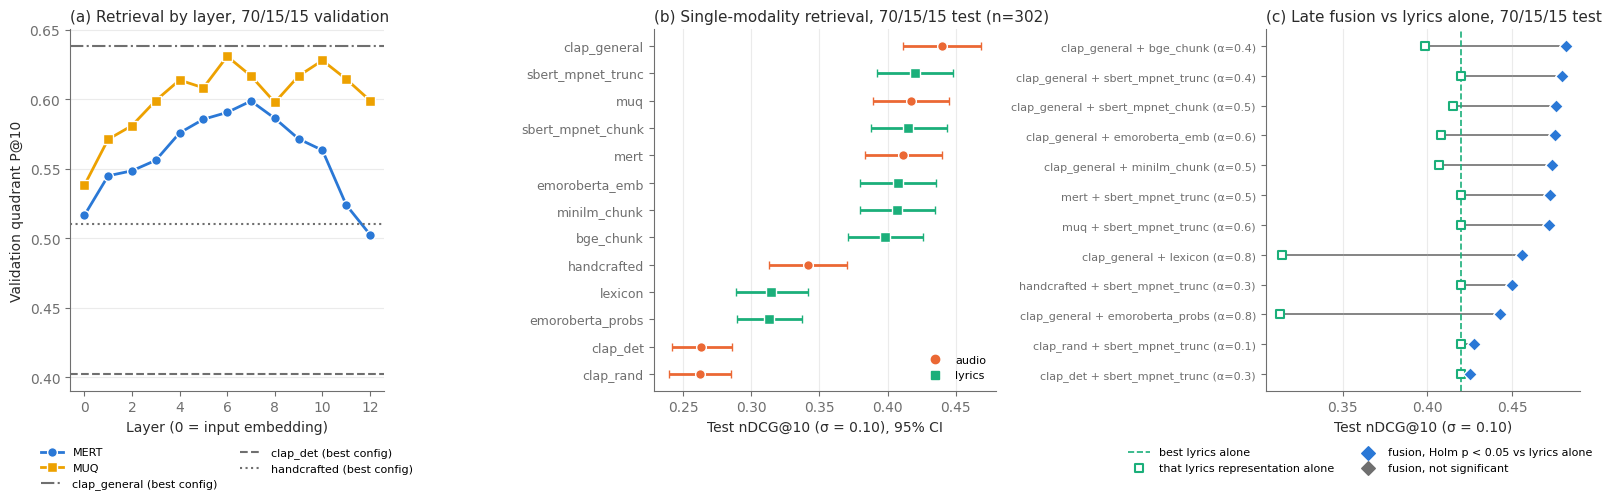

Saved: encoder_validation_sweep.csv, encoder_test_retrieval.csv, encoder_text_vs_audio_grid.csv, encoder_probes.csv, encoder_probe_layers.csv, encoder_fusion.csv, encoder_comparison.png


In [8]:
INK, MUTED = '#2b2b2b', '#6f6f6f'
C_AUDIO, C_TEXT = '#eb6834', '#1baf7a'
C_MERT, C_MUQ = '#2a78d6', '#eda100'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.labelcolor': INK, 'font.size': 10})
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), gridspec_kw={'width_ratios': [1.1, 1.2, 1.1]})

# (a) layer curves: validation P@10 (retrieval, best preprocessing per layer), 70/15/15
ax = axes[0]
for fam, c, mk in [('mert', C_MERT, 'o'), ('muq', C_MUQ, 's')]:
    g = val[(val.split == '70/15/15') & (val.family == fam)].copy()
    g['layer'] = g.rep.str.split('_L').str[1].astype(int)
    best_by_layer = g.groupby('layer').val_quad_p10.max()
    ax.plot(best_by_layer.index, best_by_layer.values, marker=mk, color=c, lw=2, ms=7, mec='white', label=fam.upper())
for fam, ls in [('clap_general', '-.'), ('clap_det', '--'), ('handcrafted', ':')]:
    v = val[(val.split == '70/15/15') & (val.family == fam)].val_quad_p10.max()
    ax.axhline(v, color=MUTED, ls=ls, lw=1.5, label=f'{fam} (best config)')
ax.set_xlabel('Layer (0 = input embedding)'); ax.set_ylabel('Validation quadrant P@10')
ax.set_title('(a) Retrieval by layer, 70/15/15 validation', loc='left', fontsize=11, color=INK)
ax.legend(fontsize=8, frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.13)); ax.grid(axis='y', alpha=0.25)

# (b) test nDCG@10 per representation, 70/15/15
ax = axes[1]
s = test_single[test_single.split == '70/15/15'].sort_values('ndcg')
y = np.arange(len(s))
for yi, (_, r) in zip(y, s.iterrows()):
    c = C_AUDIO if r.modality == 'audio' else C_TEXT
    ax.errorbar(r.ndcg, yi, xerr=[[r.ndcg - r.ndcg_lo], [r.ndcg_hi - r.ndcg]], fmt='o' if r.modality == 'audio' else 's',
                color=c, ms=7, capsize=3, mec='white', lw=2)
ax.set_yticks(y); ax.set_yticklabels(s.family, fontsize=9)
ax.plot([], [], 'o', color=C_AUDIO, label='audio'); ax.plot([], [], 's', color=C_TEXT, label='lyrics')
ax.set_xlabel('Test nDCG@10 (σ = 0.10), 95% CI')
ax.set_title(f"(b) Single-modality retrieval, 70/15/15 test (n={s.n.iloc[0]})", loc='left', fontsize=11, color=INK)
ax.legend(fontsize=8, frameon=False, loc='lower right'); ax.grid(axis='x', alpha=0.25)

# (c) absolute nDCG@10 of each late fusion, next to its text representation alone, 70/15/15
#     (a gain plot made fusions with weak text baselines look best; absolute scores avoid that)
ax = axes[2]
s = fusion[fusion.split == '70/15/15'].sort_values('ndcg')
y = np.arange(len(s))
best_text_alone = test_single[(test_single.split == '70/15/15') & (test_single.modality == 'text')].ndcg.max()
ax.axvline(best_text_alone, color=C_TEXT, ls='--', lw=1.2, label='best lyrics alone')
for yi, (_, r) in zip(y, s.iterrows()):
    sig = r.ndcg_p_holm < 0.05
    ax.plot([r.ndcg_text_alone, r.ndcg], [yi, yi], color=MUTED, lw=1.2, zorder=1)
    ax.scatter(r.ndcg_text_alone, yi, marker='s', s=40, facecolor='white', edgecolor=C_TEXT, lw=1.5, zorder=2)
    ax.scatter(r.ndcg, yi, marker='D', s=48, color=C_MERT if sig else MUTED, edgecolor='white', zorder=3)
ax.set_yticks(y); ax.set_yticklabels([f'{a} + {t} (α={al})' for a, t, al in zip(s.audio, s.text, s.alpha)], fontsize=8)
ax.scatter([], [], marker='s', s=40, facecolor='white', edgecolor=C_TEXT, lw=1.5, label='that lyrics representation alone')
ax.scatter([], [], marker='D', s=48, color=C_MERT, label='fusion, Holm p < 0.05 vs lyrics alone')
ax.scatter([], [], marker='D', s=48, color=MUTED, label='fusion, not significant')
ax.set_xlabel('Test nDCG@10 (σ = 0.10)')
ax.set_title('(c) Late fusion vs lyrics alone, 70/15/15 test', loc='left', fontsize=11, color=INK)
ax.legend(fontsize=8, frameon=False, ncol=2, loc='upper center', bbox_to_anchor=(0.3, -0.13)); ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'encoder_comparison_artist_cg.png'), dpi=200, bbox_inches='tight')
plt.show()
layers.to_csv(os.path.join(OUT_DIR, 'encoder_probe_layers_artist_cg.csv'), index=False)
print('Saved: encoder_validation_sweep.csv, encoder_test_retrieval.csv, encoder_text_vs_audio_grid.csv, '
      'encoder_probes.csv, encoder_probe_layers.csv, encoder_fusion.csv, encoder_comparison.png')